<div style="width: 100%; overflow: hidden;">
    <a href="http://www.uc.pt/fctuc/dei/">
    <div style="display: block;margin-left: auto;margin-right: auto; width: 50%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>
    </a>
</div>

## Project 1 - ACA 2025

Authors: Ivo Simões (2024160048), António Marques (2022259825)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
from tqdm import tqdm
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision.transforms import v2  # Note: v2 is faster and more robust
from torchvision.models.efficientnet import efficientnet_b3, EfficientNet_B3_Weights

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import f1_score, precision_score, recall_score
from mlxtend.plotting import plot_confusion_matrix

from medmnist import INFO, __version__, HOMEPAGE
from medmnist.dataset import DermaMNIST

# Reproducibility
np.random.seed(42)
torch.manual_seed(42);

In [2]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [3]:
# Defining a path to save best models
PATH = Path("models")
PATH.mkdir(parents=True, exist_ok=True)

In [4]:
# Parameters

# Image size
MLP_IMG_SIZE = 28
CNN_IMG_SIZE = 56  # Defines pixel height and width of resized images in DA
EFF_IMG_SIZE = 300  # EfficientNet's input image size

# Batch size
BATCH_SIZE = 128  # Dataloaders' batch size
EFF_BATCH_SIZE = 64  # EfficientNet's batch size

# Undersampling
UND_SIZE = 0.3  # Percentage (0-1) of samples of majority class to remove

# Optimizers
LR = 0.001  # General learning rate for all optimizers
EFF_LR = 2e-5  # EfficientNet's learning rate (for fine tuning)
WEIGHT_DECAY = 1e-4  # Regularization (genealization technique) for optimizers
EFF_WEIGHT_DECAY = 1e-5  # EfficientNet's regularization (lower for fine tuning)
MOMENTUM = 0.9  # For SGD and RMSprop (to speed up convergence and avoid local minima)

# Epoch number (approx. number where overfitting starts)
MLP_EPOCHS = 100
CNN_EPOCHS = 50
EFF_EPOCHS = 50

# Data Preparation

## Dataset Metadata

In [6]:
print(f"MedMNIST v{__version__} @ {HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [5]:
data_flag = 'dermamnist'

# INFO has metadata about the various datasets of the many medmnist library datasets
# Here, we retrieve metadata about our dataset of interest (DermaMNIST)
info = INFO[data_flag]  # Metadata about DermaMNIST
labels = info['label']
task = info['task']
n_samples = info['n_samples']
n_channels = info['n_channels']
n_classes = len(info['label'])

print(f"Task: {task}")
print(f"Image Color Channels: {n_channels}")
print(f"Data Splitting: {n_samples}")
print(f"Number of classes: {n_classes}")
pprint(labels)

Task: multi-class
Image Color Channels: 3
Data Splitting: {'train': 7007, 'val': 1003, 'test': 2005}
Number of classes: 7
{'0': 'actinic keratoses and intraepithelial carcinoma',
 '1': 'basal cell carcinoma',
 '2': 'benign keratosis-like lesions',
 '3': 'dermatofibroma',
 '4': 'melanoma',
 '5': 'melanocytic nevi',
 '6': 'vascular lesions'}


## Data Download and Splitting

In [6]:
# Transform images to torch tensors
data_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

# Download the dataset (into the different splits)
train_dataset = DermaMNIST(split='train',
                           transform=data_transform,
                           download=True)
val_dataset = DermaMNIST(split='val',
                         transform=data_transform,
                         download=True)
test_dataset = DermaMNIST(split='test',
                          transform=data_transform,
                          download=True)
pil_dataset = DermaMNIST(split='train',
                         download=True)

Using downloaded and verified file: /root/.medmnist/dermamnist.npz
Using downloaded and verified file: /root/.medmnist/dermamnist.npz
Using downloaded and verified file: /root/.medmnist/dermamnist.npz
Using downloaded and verified file: /root/.medmnist/dermamnist.npz


In [7]:
print(train_dataset)
print("===================")
print(val_dataset)
print("===================")
print(test_dataset)

Dataset DermaMNIST of size 28 (dermamnist)
    Number of datapoints: 7007
    Root location: /root/.medmnist
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'}
    Number of samples: {'train': 7007, 'val': 1003, 'test': 2005}
    Description: The DermaMNIST is based on the HAM10000, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. The dataset consists of 10,015 dermatoscopic images categorized as 7 different diseases, formulized as a multi-class classification task. We split the images into training, validation and test set with a ratio of 7:1:2. The source images of 3×600×450 are resized into 3×28×28.
    License: CC BY-NC 4.0
Dataset DermaMNIST of size 28 (dermamnist)
    Number of datapoints: 100

In [10]:
# AI code to compute mean and standard deviation of color intensity in train dataset
dataloader = DataLoader(train_dataset, batch_size=32, shuffle=False)

def compute_mean_std(dataloader):
    channels_sum, channels_squared_sum, num_batches = 0, 0, 0

    for data, _ in dataloader:
        # data shape: [batch_size, channels, height, width]
        channels_sum += torch.mean(data, dim=[0, 2, 3])           # Mean per channel
        channels_squared_sum += torch.mean(data**2, dim=[0, 2, 3]) # Mean of squares per channel
        num_batches += 1

    mean = channels_sum / num_batches
    std = (channels_squared_sum / num_batches - mean**2)**0.5

    return mean, std

compute_mean_std(dataloader)

(tensor([0.7631, 0.5381, 0.5614]), tensor([0.1366, 0.1543, 0.1692]))

## Data Visualization and Analysis

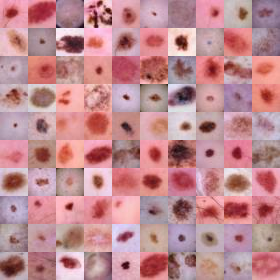

In [11]:
# Initial look at the dataset's images (100 training samples)
train_dataset.montage(length=10)

{'0': 'actinic keratoses and intraepithelial carcinoma',
 '1': 'basal cell carcinoma',
 '2': 'benign keratosis-like lesions',
 '3': 'dermatofibroma',
 '4': 'melanoma',
 '5': 'melanocytic nevi',
 '6': 'vascular lesions'}


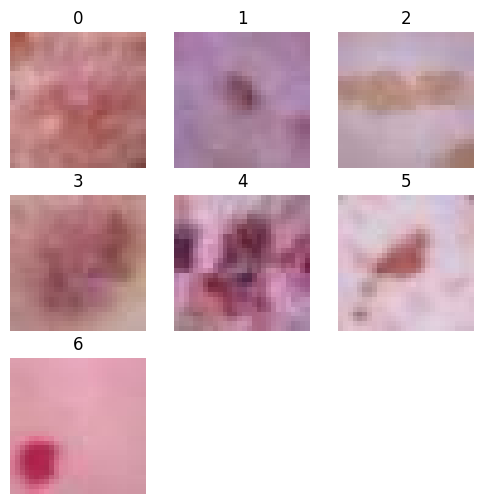

In [12]:
# Get a random sample from each class
indices = [np.where(train_dataset.labels == i)[0] for i in range(n_classes)]
random_idx = [indices[i][np.random.randint(0, len(indices[i]), 1)[0]] for i in range(n_classes)]

# Print a random sample of each class
pprint(labels)
fig = plt.figure(figsize=(6, 6))
rows, cols = 3, 3
for i in range(1, len(random_idx)+1):
    image = train_dataset.imgs[random_idx[i-1]]
    fig.add_subplot(rows, cols, i)
    plt.imshow(X=image)
    plt.axis(False)
    plt.title(i-1)

In [13]:
# Check image dimension consistency
print("Shapes of the datasets:")
print(f"Training Set: {train_dataset.imgs.shape}")
print(f"Validaion Set: {val_dataset.imgs.shape}")
print(f"Test Set: {test_dataset.imgs.shape}")

Shapes of the datasets:
Training Set: (7007, 28, 28, 3)
Validaion Set: (1003, 28, 28, 3)
Test Set: (2005, 28, 28, 3)


{'0': 'actinic keratoses and intraepithelial carcinoma',
 '1': 'basal cell carcinoma',
 '2': 'benign keratosis-like lesions',
 '3': 'dermatofibroma',
 '4': 'melanoma',
 '5': 'melanocytic nevi',
 '6': 'vascular lesions'}


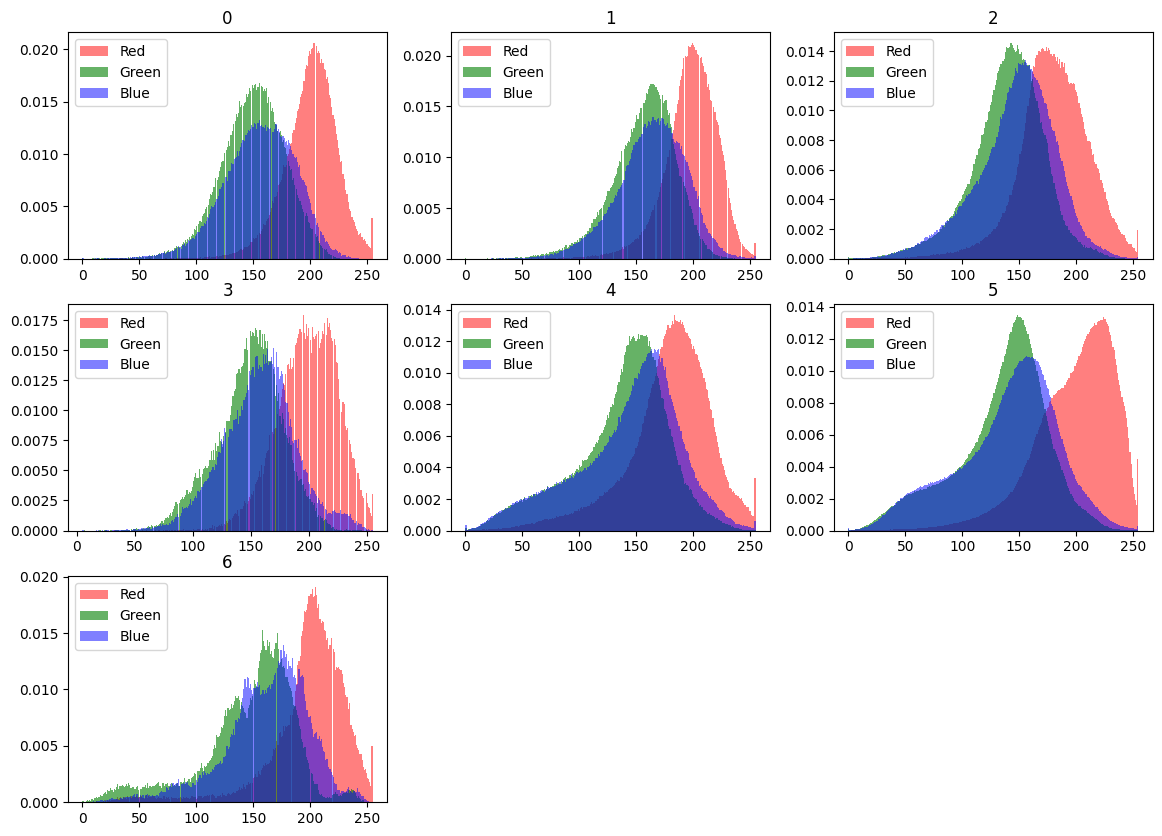

In [14]:
# Density plots of color distribution per class
pprint(labels)
fig = plt.figure(figsize=(14, 10))
rows, cols = 3, 3
for i in range(1, n_classes+1):
    red = train_dataset.imgs[indices[i-1]][:, :, :, 0]
    green = train_dataset.imgs[indices[i-1]][:, :, :, 1]
    blue = train_dataset.imgs[indices[i-1]][:, :, :, 2]

    # Plots were made with the aid of AI
    fig.add_subplot(rows, cols, i)
    plt.hist(red.flatten(), bins=256, color='red', alpha=0.5, density=True, label='Red')
    plt.hist(green.flatten(), bins=256, color='green', alpha=0.6, density=True, label='Green')
    plt.hist(blue.flatten(), bins=256, color='blue', alpha=0.5, density=True, label='Blue')
    plt.title(i-1)
    plt.legend();
plt.show()

0 - actinic keratoses and intraepithelial carcinoma: 228
1 - basal cell carcinoma: 359
2 - benign keratosis-like lesions: 769
3 - dermatofibroma: 80
4 - melanoma: 779
5 - melanocytic nevi: 4693
6 - vascular lesions: 99


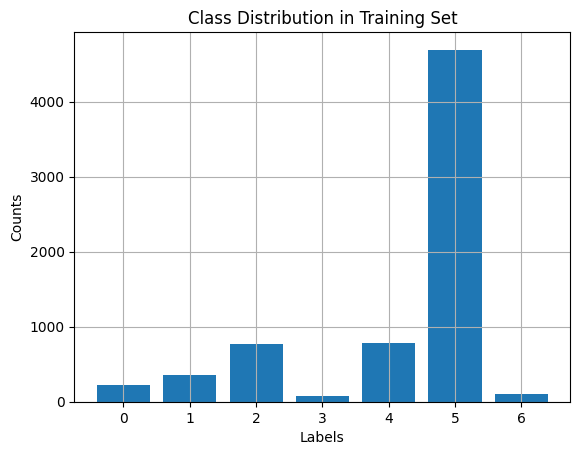

In [15]:
# Class distribution in the training set
num_labels, counts = np.unique(train_dataset.labels, return_counts=True)
for i, count in enumerate(counts):
    print(f"{i} - {labels[str(i)]}: {count}")

# Plotting class distribution
plt.figure()
plt.bar(x=num_labels, height=counts)
plt.grid(True)
plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Class Distribution in Training Set')
plt.show()

In [8]:
# Transformations used to augment, resize and normalize data
transform_aug = v2.Compose([
    v2.RandomHorizontalFlip(p=0.2),
    v2.RandomVerticalFlip(p=0.2),
    v2.RandomAdjustSharpness(sharpness_factor=2, p=0.2),
    v2.GaussianBlur(kernel_size=3, sigma=0.3),
])

transform_cnn = v2.Compose([
    v2.Resize((CNN_IMG_SIZE, CNN_IMG_SIZE)),
    v2.Normalize(  # Precomputed mean and std for training set
        mean=[0.763, 0.538, 0.561],
        std=[0.136, 0.154, 0.169]
    )
])

transform_mlp = v2.Compose([
    v2.Normalize(  # Precomputed mean and std for training set
        mean=[0.763, 0.538, 0.561],
        std=[0.136, 0.154, 0.169]
    )
])

In [10]:
# Transformations performed by pre-trained model
EfficientNet_B3_Weights.DEFAULT.transforms()

ImageClassification(
    crop_size=[300]
    resize_size=[320]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [11]:
# Random undersampling of majority class
idx = np.where(train_dataset.labels == 5)[0]  # Get samples with label 5
rand_idx = np.random.choice(idx, int(len(idx)*UND_SIZE), replace=False)  # Get % of samples with label 5
sample_subset = np.setdiff1d(np.arange(len(train_dataset)), rand_idx)  # Eliminate % of samples with label 5
undersampled_train = Subset(train_dataset, sample_subset)  # Get new undersampled dataset

In [12]:
# Load data into DataLoaders
train_loader = DataLoader(dataset=undersampled_train,
                          batch_size=BATCH_SIZE,
                          shuffle=True)
eff_train_loader = DataLoader(dataset=undersampled_train,
                              batch_size=EFF_BATCH_SIZE,
                              shuffle=True)
val_loader = DataLoader(dataset=val_dataset,
                        batch_size=BATCH_SIZE,
                        shuffle=False)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False)

# Models

In [20]:
class MLP(nn.Module):
    ''' Creates a MLP for DermaMNIST classification (customized hidden layers).
        Takes in image shape (C x H x W) (in) and number of classes (out) as arguments. '''
    def __init__(self,
                 in_features: tuple[int, int, int],  # C x H x W
                 out_features: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            # Note: The comments don't take batch size into consideration (add 1 dim before others)
            nn.Flatten(),  # (3, 28, 28) -> (2352, )
            nn.Linear(in_features=in_features[0]*in_features[1]*in_features[2],
                      out_features=256),  # (2352, ) -> (256, )
            nn.Sigmoid(),  # (256, ) -> (256, )

            nn.Linear(in_features=256, out_features=out_features),  # (256, ) -> (7, )
        )

    def forward(self, x: torch.Tensor):
        ''' Propagates the input tensor (x) forward along the MLP.
            Note: Ensure that x is of shape (C x H x W). '''
        return self.layer_stack(x)

In [21]:
class CNN(nn.Module):
    ''' Creates a CNN for DermaMNIST classification (customized hidden layers).
        Takes in image shape (C x H x W) (in) and number of classes (out) as arguments. '''
    def __init__(self,
                 in_features: tuple[int, int, int],  # C x H x W
                 out_features: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            # Note: The comments don't take batch size into consideration (add 1 dim before others)
            nn.Conv2d(in_channels=in_features[0], out_channels=16,
                      kernel_size=(3, 3), stride=(1, 1), padding=1),  # (3, H, W) -> (16, H, W)
            nn.ReLU(),  # (16, H, W) -> (16, H, W)
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),  # (16, H, W) -> (16, H/2, W/2)
            nn.Conv2d(in_channels=16, out_channels=32,
                      kernel_size=(3, 3), stride=(1, 1), padding=1),  # (16, H/2, W/2) -> (32, H/2, W/2)
            nn.ReLU(),  # (32, H/2, W/2) -> (32, H/2, W/2)
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),  # (32, H/2, W/2) -> (32, H/4, W/4)
            nn.Conv2d(in_channels=32, out_channels=64,
                      kernel_size=(3, 3), stride=(1, 1), padding=1),  # (32, H/4, W/4) -> (64, H/4, W/4)
            nn.ReLU(),  # (64, H/4, W/4) -> (64, H/4, W/4)
            nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2)),  #  (64, H/4, W/4) -> (64, H/8, W/8)
            nn.Dropout2d(p=0.2),

            nn.Flatten(),  # (64, H/8, W/8) -> (64*(H/8)*(W/8), )
            nn.Linear(in_features=64*(CNN_IMG_SIZE//8)**2, out_features=out_features),  # (64*(H/8)*(W/8), ) -> (7, )
        )

    def forward(self, x: torch.Tensor):
        ''' Propagates the input tensor (x) forward along the MLP.
            Note: Ensure that x is of shape (3 x 28 x 28). '''
        return self.layer_stack(x)

In [13]:
# Pre-trained model (EfficientNetB3)
weights = EfficientNet_B3_Weights.DEFAULT
preprocess = weights.transforms()
eff_net = efficientnet_b3(weights=weights)

# Freeze all layers
for param in eff_net.parameters():
    param.requires_grad = False

# Note: EfficientNetB3 has 8 convolution blocks
# Unfreeze the later blocks (task specific)
for param in eff_net.features[4:].parameters():
    param.requires_grad = True

# Change number of output classes (by adapting FC layer)
eff_net.classifier = nn.Sequential(
    nn.Dropout(p=0.3, inplace=True),
    nn.Linear(in_features=1536, out_features=n_classes)
)

eff_net.to(device)
eff_net

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
            (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActiv

In [23]:
# Random prediction with first batch
mlp = MLP(in_features=(3, 28, 28), out_features=n_classes).to(device)
X, y_true = list(iter(train_loader))[0][0], list(iter(train_loader))[0][1]

with torch.inference_mode():
    X = transform_mlp(X).to(device)
    y = mlp(X)
y[:5]

tensor([[ 0.0586,  0.7885, -0.4125,  0.0613,  0.5826,  0.0938,  0.2236],
        [ 0.0604,  0.7020, -0.4318,  0.0876,  0.5373,  0.1956,  0.1405],
        [ 0.0519,  0.6688, -0.3900,  0.0667,  0.5509,  0.0824,  0.1998],
        [ 0.0840,  0.6839, -0.3582, -0.0315,  0.5242,  0.1027,  0.2079],
        [ 0.1164,  0.7846, -0.4882, -0.0262,  0.4669,  0.2108,  0.2659]],
       device='cuda:0')

In [24]:
# Random prediction with first batch
cnn = CNN(in_features=(3, CNN_IMG_SIZE, CNN_IMG_SIZE), out_features=n_classes).to(device)
X, y_true = list(iter(train_loader))[0][0], list(iter(train_loader))[0][1]

with torch.inference_mode():
    X = transform_cnn(X).to(device)
    y = cnn(X)
y[:5]

tensor([[ 0.0505,  0.1222, -0.1390,  0.0490,  0.1475,  0.1150, -0.0357],
        [ 0.0505,  0.0667, -0.0666, -0.0100,  0.0187,  0.0967, -0.0239],
        [ 0.0672,  0.0584, -0.1149,  0.0225,  0.0817,  0.1496, -0.0041],
        [ 0.1642, -0.0330, -0.1723,  0.1067,  0.1517,  0.2336, -0.0171],
        [ 0.0552,  0.0098, -0.1630,  0.0926,  0.0729,  0.0951, -0.0078]],
       device='cuda:0')

# Training the Models

In [14]:
# Loss Functions and Optimizers (to be used)
loss_fns = ['CEL', 'MML']
optimizers = ['Adam', 'RMSprop', 'SGD']

In [15]:
def accuracy_fn(y_true: torch.Tensor, y_pred: torch.Tensor):
    ''' Computes percentage accuracy of predicted labels. '''
    correct = torch.sum((y_pred == y_true))
    acc = correct / len(y_true)
    return acc * 100

In [16]:
def augment(X: torch.Tensor, y: torch.Tensor, resize_model: str):
    ''' Performs transformations to training images for data augmentation.
        The transforms are defined in the Data Preparation section. '''
    new_X = None
    if resize_model == 'cnn':
        new_X = torch.zeros((len(X), 3, CNN_IMG_SIZE, CNN_IMG_SIZE))
    elif resize_model == 'mlp':
        new_X = torch.zeros((len(X), 3, 28, 28))
    else:
        new_X = torch.zeros((len(X), 3, EFF_IMG_SIZE, EFF_IMG_SIZE))

    for i in range(len(X)):
        # Perform augments (transform and perturb images)
        X[i] = transform_aug(X[i])

        # Resize and normalize
        if resize_model == 'mlp':
            new_X[i] = transform_mlp(X[i])
        elif resize_model == 'cnn':
            new_X[i] = transform_cnn(X[i])
        else:
            new_X[i] = preprocess(X[i])
    return new_X

In [17]:
def train_step(model: nn.Module,
               train_dataloader: DataLoader,
               resize_model: str,
               loss_fn: nn.Module,
               optimizer: optim,
               accuracy_fn,
               device: str = device):
    ''' Performs a training step with the given dataloader. '''
    model.train()

    train_acc = 0
    train_loss = 0
    for X, y in train_dataloader:
        # Reset gradients
        model.zero_grad()

        # Augmentations
        new_X = augment(X.clone(), y, resize_model)

        # Everything on the same device
        new_X, y = new_X.to(device), torch.flatten(y).to(device)

        # Prediction
        train_logits = model(new_X)

        # Accuracy
        train_probs = torch.softmax(train_logits, dim=1)
        train_preds = train_probs.argmax(dim=1)
        train_acc += accuracy_fn(y_true=y, y_pred=train_preds)

        # Loss
        loss = loss_fn(train_logits, y)
        train_loss += loss
        loss.backward()

        # Optimizer
        optimizer.step()

    train_acc /= len(train_dataloader)
    train_loss /= len(train_dataloader)
    return train_acc, train_loss.detach()

In [18]:
def val_step(model: nn.Module,
             val_dataloader: DataLoader,
             resize_model: str,
             loss_fn: nn.Module,
             accuracy_fn,
             device: str = device):
    ''' Performs a validation step with the given dataloader. '''
    model.eval()

    with torch.inference_mode():
        val_loss = 0
        val_acc = 0
        for X, y in val_dataloader:
            # Resize and Normalization
            new_X = None
            if resize_model == 'mlp':
                new_X = transform_mlp(X)
            elif resize_model == 'cnn':
                new_X = transform_cnn(X)
            else:
                new_X = preprocess(X)

            # Everything on the same device
            new_X, y = new_X.to(device), torch.flatten(y).to(device)

            val_logits = model(new_X)
            val_probs = torch.softmax(val_logits, dim=1)
            val_preds = val_probs.argmax(dim=1)
            val_acc += accuracy_fn(y_true=y, y_pred=val_preds)
            val_loss += loss_fn(val_logits, y)

        val_acc /= len(val_dataloader)
        val_loss /= len(val_dataloader)
    return val_acc, val_loss

In [19]:
def train(epochs: int,
          model: nn.Module,
          pair: tuple[str, str],
          train_dataloader: DataLoader,
          val_dataloader: DataLoader,
          resize_model: str,
          loss_fn: nn.Module,
          optimizer: optim,
          accuracy_fn,
          device: str = device):
    ''' Defines the training loop. '''

    best_acc = 0
    best_loss = float('inf')
    epoch_values = []
    train_loss_values = []
    train_acc_values = []
    val_loss_values = []
    val_acc_values = []

    for epoch in tqdm(range(1, epochs+1)):
        train_acc, train_loss = train_step(model=model,
                                           train_dataloader=train_dataloader,
                                           resize_model=resize_model,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           accuracy_fn=accuracy_fn,
                                           device=device)
        val_acc, val_loss = val_step(model=model,
                                     val_dataloader=val_dataloader,
                                     resize_model=resize_model,
                                     loss_fn=loss_fn,
                                     accuracy_fn=accuracy_fn,
                                     device=device)

        epoch_values.append(epoch)
        train_loss_values.append(train_loss.to('cpu').item())
        train_acc_values.append(train_acc.to('cpu').item()/100)
        val_loss_values.append(val_loss.to('cpu').item())
        val_acc_values.append(val_acc.to('cpu').item()/100)

        if val_acc > best_acc and val_loss < best_loss:
            print(f"Epoch: {epoch}")
            print("---------------")
            print(f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f}")
            print(f"Val loss: {val_loss:.4f} | Val acc: {val_acc:.4f}\n")

            best_acc = val_acc
            best_loss = val_loss
            print("Saving model...\n")
            SAVING_MODEL_PATH = PATH / f"{resize_model.upper()}_{str(pair)}.pth"
            torch.save(model.state_dict(), SAVING_MODEL_PATH)

    return epoch_values, train_loss_values, train_acc_values, val_loss_values, val_acc_values

In [31]:
# Train and gather results for all combinations of loss functions and optimizers using MLP
mlp_results = {}
for loss in loss_fns:
    mlp_results[loss] = {}
    for opt in optimizers:
          mlp_results[loss][opt] = {}

for loss in loss_fns:
    loss_fn = None
    if loss == 'CEL':
          loss_fn = nn.CrossEntropyLoss()
    else:
          loss_fn = nn.MultiMarginLoss()
    for opt in optimizers:
          mlp = MLP(in_features=(3, 28, 28), out_features=n_classes).to(device)
          optimizer = None
          if opt == 'Adam':
                optimizer = optim.Adam(params=mlp.parameters(),
                                        lr=LR,
                                        weight_decay=WEIGHT_DECAY)
          elif opt == 'RMSprop':
                optimizer = optim.RMSprop(params=mlp.parameters(),
                                          lr=LR,
                                          weight_decay=WEIGHT_DECAY,
                                          momentum=MOMENTUM)
          else:
                optimizer = optim.SGD(params=mlp.parameters(),
                                      lr=LR,
                                      weight_decay=WEIGHT_DECAY,
                                      momentum=MOMENTUM)
          epochs, train_loss, train_acc, val_loss, val_acc = train(epochs=MLP_EPOCHS,
                                                                    model=mlp,
                                                                    pair=(opt, loss),
                                                                    train_dataloader=train_loader,
                                                                    val_dataloader=val_loader,
                                                                    resize_model='mlp',
                                                                    loss_fn=loss_fn,
                                                                    optimizer=optimizer,
                                                                    accuracy_fn=accuracy_fn,
                                                                    device=device)
          mlp_results[loss][opt]['train_loss'] = train_loss
          mlp_results[loss][opt]['train_acc'] = train_acc
          mlp_results[loss][opt]['val_loss'] = val_loss
          mlp_results[loss][opt]['val_acc'] = val_acc

  1%|          | 1/100 [00:04<07:47,  4.72s/it]

Epoch: 1
---------------
Train loss: 1.1336 | Train acc: 59.5881
Val loss: 0.9064 | Val acc: 68.8988

Saving model...



  2%|▏         | 2/100 [00:09<07:34,  4.64s/it]

Epoch: 2
---------------
Train loss: 1.0248 | Train acc: 62.1212
Val loss: 0.8667 | Val acc: 70.0497

Saving model...



  5%|▌         | 5/100 [00:24<07:49,  4.94s/it]

Epoch: 5
---------------
Train loss: 0.9303 | Train acc: 64.7313
Val loss: 0.8273 | Val acc: 70.7926

Saving model...



... (119 outputs left out)

Epoch: 58
---------------
Train loss: 0.2527 | Train acc: 61.2393
Val loss: 0.2084 | Val acc: 69.9903

Saving model...



 84%|████████▍ | 84/100 [06:41<01:15,  4.73s/it]

Epoch: 84
---------------
Train loss: 0.2448 | Train acc: 61.9555
Val loss: 0.2022 | Val acc: 70.0880

Saving model...



100%|██████████| 100/100 [07:56<00:00,  4.77s/it]


In [32]:
# Train and gather results for all combinations of loss functions and optimizers using CNN
cnn_results = {}
for loss in loss_fns:
      cnn_results[loss] = {}
      for opt in optimizers:
            cnn_results[loss][opt] = {}

for loss in loss_fns:
      loss_fn = None
      if loss == 'CEL':
            loss_fn = nn.CrossEntropyLoss()
      else:
            loss_fn = nn.MultiMarginLoss()
      for opt in optimizers:
            cnn = CNN(in_features=(3, CNN_IMG_SIZE, CNN_IMG_SIZE), out_features=n_classes).to(device)
            optimizer = None
            if opt == 'Adam':
                  optimizer = optim.Adam(params=cnn.parameters(),
                                         lr=LR,
                                         weight_decay=WEIGHT_DECAY)
            elif opt == 'RMSprop':
                  optimizer = optim.RMSprop(params=cnn.parameters(),
                                            lr=LR,
                                            weight_decay=WEIGHT_DECAY,
                                            momentum=MOMENTUM)
            else:
                  optimizer = optim.SGD(params=cnn.parameters(),
                                        lr=LR,
                                        weight_decay=WEIGHT_DECAY,
                                        momentum=MOMENTUM)
            epochs, train_loss, train_acc, val_loss, val_acc = train(epochs=CNN_EPOCHS,
                                                                     model=cnn,
                                                                     pair=(opt, loss),
                                                                     train_dataloader=train_loader,
                                                                     val_dataloader=val_loader,
                                                                     resize_model='cnn',
                                                                     loss_fn=loss_fn,
                                                                     optimizer=optimizer,
                                                                     accuracy_fn=accuracy_fn,
                                                                     device=device)
            cnn_results[loss][opt]['train_loss'] = train_loss
            cnn_results[loss][opt]['train_acc'] = train_acc
            cnn_results[loss][opt]['val_loss'] = val_loss
            cnn_results[loss][opt]['val_acc'] = val_acc

  2%|▏         | 1/50 [00:06<05:07,  6.27s/it]

Epoch: 1
---------------
Train loss: 1.1646 | Train acc: 58.4576
Val loss: 0.8927 | Val acc: 69.9520

Saving model...



  6%|▌         | 3/50 [00:18<04:46,  6.09s/it]

Epoch: 3
---------------
Train loss: 0.9576 | Train acc: 63.3641
Val loss: 0.8172 | Val acc: 70.0880

Saving model...



 10%|█         | 5/50 [00:30<04:30,  6.00s/it]

Epoch: 5
---------------
Train loss: 0.8863 | Train acc: 65.9150
Val loss: 0.7405 | Val acc: 72.0028

Saving model...



... (133 outputs left out)

Epoch: 47
---------------
Train loss: 0.2420 | Train acc: 63.6896
Val loss: 0.1980 | Val acc: 70.4786

Saving model...



 96%|█████████▌| 48/50 [04:47<00:11,  5.95s/it]

Epoch: 48
---------------
Train loss: 0.2400 | Train acc: 63.9382
Val loss: 0.1972 | Val acc: 70.5763

Saving model...



100%|██████████| 50/50 [04:59<00:00,  6.00s/it]


In [20]:
# Train with lower LR and regularization for fine-tuning of model
eff_results = {}
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=eff_net.parameters(),
                       lr=EFF_LR,
                       weight_decay=EFF_WEIGHT_DECAY)
epochs, train_loss, train_acc, val_loss, val_acc = train(epochs=EFF_EPOCHS,
                                                         model=eff_net,
                                                         pair=('Adam', 'CEL'),
                                                         train_dataloader=eff_train_loader,
                                                         val_dataloader=val_loader,
                                                         resize_model='eff',
                                                         loss_fn=loss_fn,
                                                         optimizer=optimizer,
                                                         accuracy_fn=accuracy_fn,
                                                         device=device)
eff_results['train_loss'] = train_loss
eff_results['train_acc'] = train_acc
eff_results['val_loss'] = val_loss
eff_results['val_acc'] = val_acc

  2%|▏         | 1/50 [01:06<54:33, 66.80s/it]

Epoch: 1
---------------
Train loss: 1.7100 | Train acc: 45.7919
Val loss: 1.2960 | Val acc: 70.7332

Saving model...



  4%|▍         | 2/50 [02:15<54:18, 67.88s/it]

Epoch: 2
---------------
Train loss: 1.2336 | Train acc: 62.5710
Val loss: 0.9477 | Val acc: 72.2556

Saving model...



  6%|▌         | 3/50 [03:22<53:03, 67.73s/it]

Epoch: 3
---------------
Train loss: 1.0526 | Train acc: 63.4411
Val loss: 0.8412 | Val acc: 73.1728

Saving model...



... (11 outputs left out)

Epoch: 17
---------------
Train loss: 0.6110 | Train acc: 77.1484
Val loss: 0.6368 | Val acc: 77.5482

Saving model...



 42%|████▏     | 21/50 [23:35<32:33, 67.35s/it]

Epoch: 21
---------------
Train loss: 0.5395 | Train acc: 80.1491
Val loss: 0.6319 | Val acc: 78.0365

Saving model...



100%|██████████| 50/50 [56:05<00:00, 67.30s/it]


# Model Evaluation

In [21]:
def test_step(model: nn.Module,
              test_dataloader: DataLoader,
              resize_model: str,
              loss_fn: nn.Module,
              accuracy_fn,
              device: str = device):
    ''' Performs evaluation with test set. '''
    model.eval()

    with torch.inference_mode():
        test_loss = 0
        test_acc = 0
        all_preds = []
        all_labels = []
        for X, y in test_dataloader:
            # Resize and Normalize
            new_X = None
            if resize_model == 'mlp':
                new_X = transform_mlp(X)
            elif resize_model == 'cnn':
                new_X = transform_cnn(X)
            else:
                new_X = preprocess(X)

            new_X, y = new_X.to(device), torch.flatten(y).to(device)

            test_logits = model(new_X)
            test_probs = torch.softmax(test_logits, dim=1)
            test_preds = test_probs.argmax(dim=1)
            test_acc += accuracy_fn(y_true=y, y_pred=test_preds)
            test_loss += loss_fn(test_logits, y)

            all_preds.append(test_preds.tolist())
            all_labels.append(y.tolist())

        test_acc /= len(test_dataloader)
        test_loss /= len(test_dataloader)
    return test_acc.item(), test_loss.item(), all_preds, all_labels

In [22]:
def plot_performance(all_labels: torch.Tensor, all_preds: torch.Tensor):
    ''' Computes and plots the confusion matrix and classification report (precision,
        recall, F1-score, accuracy). The metrics are plotted and returned. '''
    print(len(all_preds), len(all_labels))
    all_preds = torch.tensor([pred for batch_pred in all_preds for pred in batch_pred])
    all_labels = torch.tensor([label for batch_label in all_labels for label in batch_label])
    print(all_preds.shape, all_labels.shape)

    report = classification_report(all_labels, all_preds, zero_division=0)
    conf_mat = confusion_matrix(all_labels, all_preds)
    print(report)
    plot_confusion_matrix(conf_mat=conf_mat,
                          colorbar=True,
                          show_normed=True,
                          show_absolute=True,
                          cmap='summer',
                          fontcolor_threshold=1,
                          figsize=(6, 6))

    return conf_mat, report

In [32]:
def plot_curves(result_dict: dict, model: str):
    ''' Plots the loss and accuracy curves during training and validation phases. '''
    data_sets = ['train', 'val']
    if model == 'mlp' or model == 'cnn':  # CNN and MLP are tested for 2 loss functions
        fig = plt.figure(figsize=(15, 10))
        for i in range(len(data_sets)):
            for j, loss_fn in enumerate(result_dict.keys()):
                plt.subplot(2, 2, i*2+j+1)
                colors = [('blue', 'lightblue'), ('red', 'lightcoral'), ('green', 'lightgreen')]
                color_it = iter(colors)
                for optimizer in result_dict[loss_fn].keys():
                    loss_color, acc_color = next(color_it)
                    epochs = [i for i in range(1, len(result_dict[loss_fn][optimizer]['train_loss'])+1)]
                    plt.plot(epochs, result_dict[loss_fn][optimizer][f'{data_sets[i]}_loss'],
                             c=loss_color, label=f"{optimizer} Loss")
                    plt.plot(epochs, result_dict[loss_fn][optimizer][f'{data_sets[i]}_acc'],
                             c=acc_color, label=f"{optimizer} Acc")
                    plt.legend()
                    plt.title(f'{model.upper()} {data_sets[i].capitalize()} Performance (Loss Function: {loss_fn})')
    else:
        fig = plt.figure(figsize=(15, 6))
        for i in range(len(data_sets)):
            plt.subplot(1, 2, i+1)
            epochs = np.arange(EFF_EPOCHS) + 1
            plt.plot(epochs, result_dict[f'{data_sets[i]}_loss'], c='blue', label='EffNet Loss')
            plt.plot(epochs, result_dict[f'{data_sets[i]}_acc'], c='lightblue', label='EffNet Acc')
            plt.legend()
            plt.title(f'EfficientNet {data_sets[i].capitalize()} Performance')

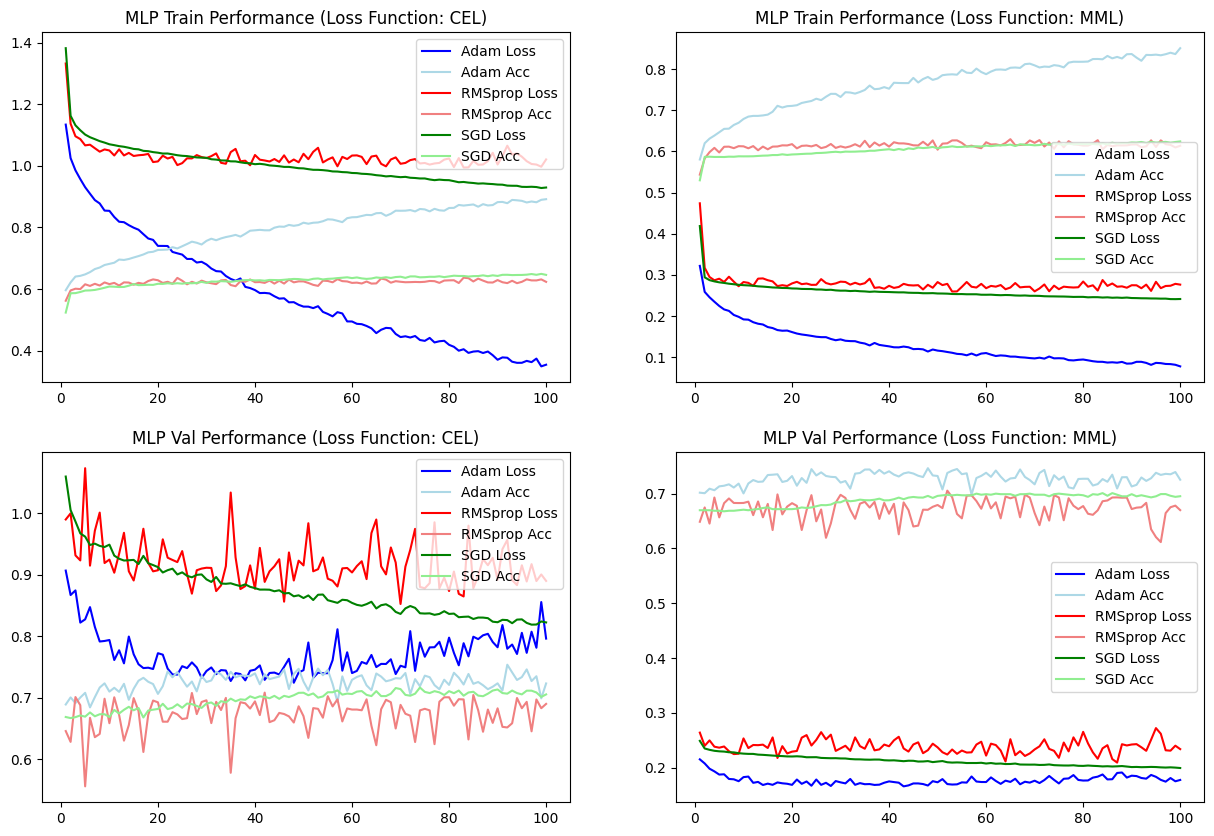

In [37]:
plot_curves(mlp_results, 'mlp')

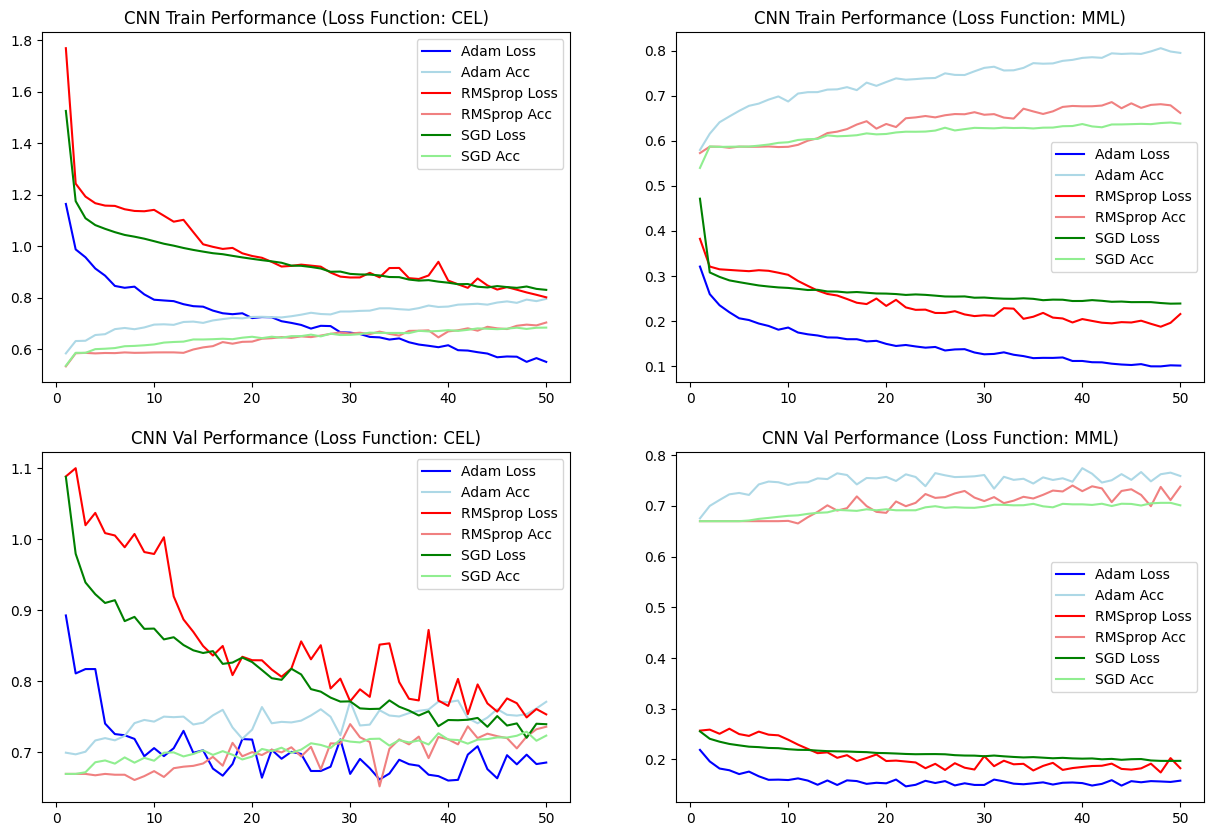

In [38]:
plot_curves(cnn_results, 'cnn')

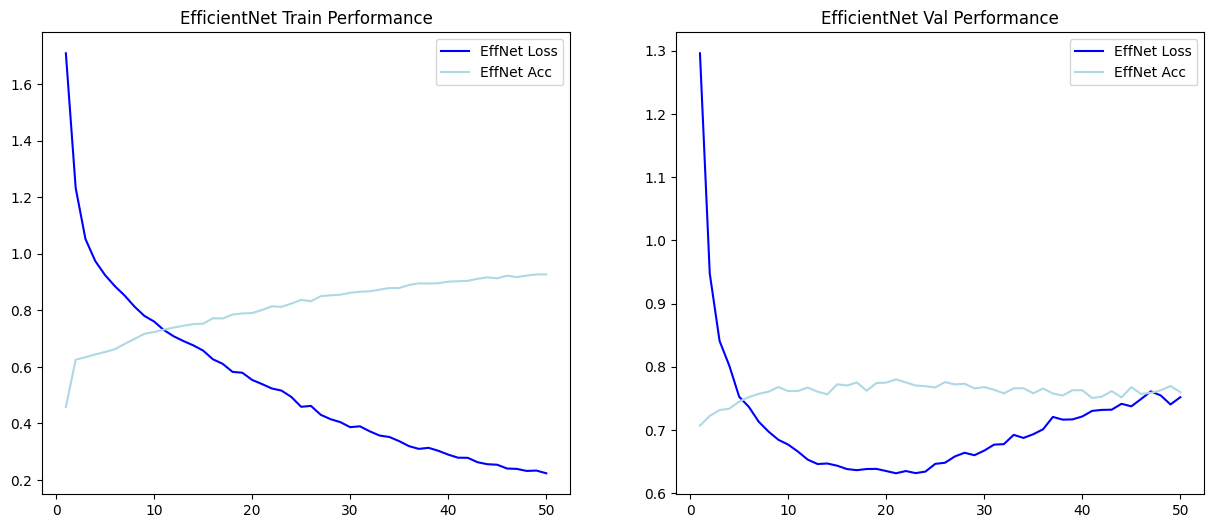

In [33]:
plot_curves(eff_results, 'other')

In [40]:
# Load best MLP model
mlp = MLP((3, 28, 28), n_classes)
mlp.load_state_dict(torch.load(PATH / f"MLP_{str(('Adam', 'CEL'))}.pth"))
mlp.to(device)

MLP(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2352, out_features=256, bias=True)
    (2): Sigmoid()
    (3): Linear(in_features=256, out_features=7, bias=True)
  )
)

In [41]:
# Load best CNN model
cnn = CNN((3, CNN_IMG_SIZE, CNN_IMG_SIZE), n_classes)
cnn.load_state_dict(torch.load(PATH / f"CNN_{str(('Adam', 'CEL'))}.pth"))
cnn.to(device)

CNN(
  (layer_stack): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Flatten(start_dim=1, end_dim=-1)
    (11): Linear(in_features=3136, out_features=7, bias=True)
  )
)

In [27]:
torch.cuda.empty_cache()

16 16
torch.Size([2005]) torch.Size([2005])
              precision    recall  f1-score   support

           0       0.26      0.45      0.33        38
           1       0.54      0.49      0.52       114
           2       0.43      0.50      0.46       191
           3       0.09      0.40      0.14         5
           4       0.35      0.40      0.37       194
           5       0.90      0.84      0.87      1446
           6       0.38      0.65      0.48        17

    accuracy                           0.73      2005
   macro avg       0.42      0.53      0.45      2005
weighted avg       0.76      0.73      0.75      2005



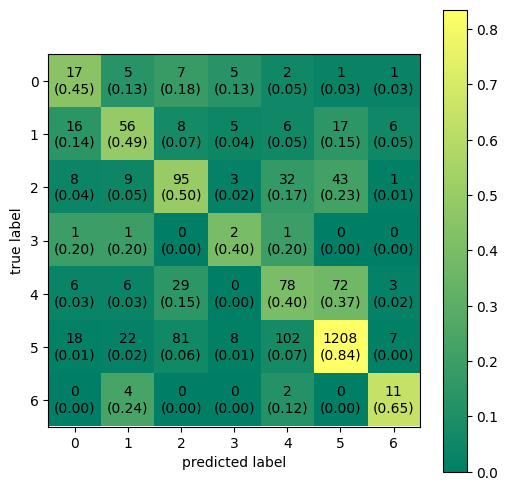

In [43]:
# Print confusion matrix and classification report for MLP
test_acc, test_loss, all_preds, all_labels = test_step(model=mlp,
                                                       test_dataloader=test_loader,
                                                       resize_model='mlp',
                                                       loss_fn=nn.CrossEntropyLoss(),
                                                       accuracy_fn=accuracy_fn,
                                                       device=device)

conf_mat, report = plot_performance(all_preds, all_labels)

16 16
torch.Size([2005]) torch.Size([2005])
              precision    recall  f1-score   support

           0       0.44      0.45      0.44        65
           1       0.62      0.50      0.55       128
           2       0.53      0.54      0.53       218
           3       0.26      0.43      0.32        14
           4       0.37      0.43      0.40       192
           5       0.88      0.87      0.88      1361
           6       0.66      0.70      0.68        27

    accuracy                           0.75      2005
   macro avg       0.54      0.56      0.54      2005
weighted avg       0.76      0.75      0.75      2005



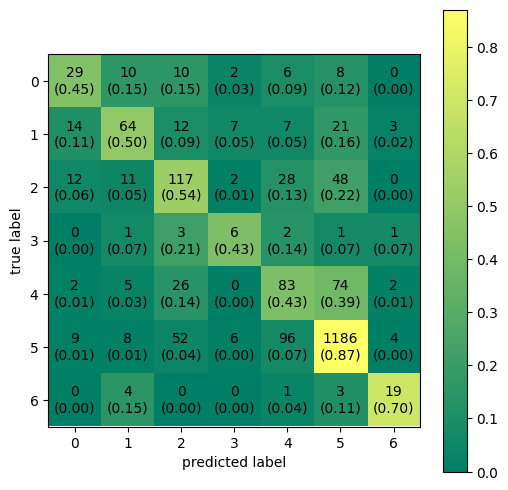

In [44]:
# Print confusion matrix and classification report for CNN
test_acc, test_loss, all_preds, all_labels = test_step(model=cnn,
                                                       test_dataloader=test_loader,
                                                       resize_model='cnn',
                                                       loss_fn=nn.CrossEntropyLoss(),
                                                       accuracy_fn=accuracy_fn,
                                                       device=device)

conf_mat, report = plot_performance(all_preds, all_labels)

16 16
torch.Size([2005]) torch.Size([2005])
              precision    recall  f1-score   support

           0       0.48      0.52      0.50        62
           1       0.56      0.52      0.54       112
           2       0.50      0.53      0.51       208
           3       0.43      0.42      0.43        24
           4       0.53      0.48      0.50       247
           5       0.88      0.89      0.88      1322
           6       0.79      0.77      0.78        30

    accuracy                           0.76      2005
   macro avg       0.60      0.59      0.59      2005
weighted avg       0.76      0.76      0.76      2005



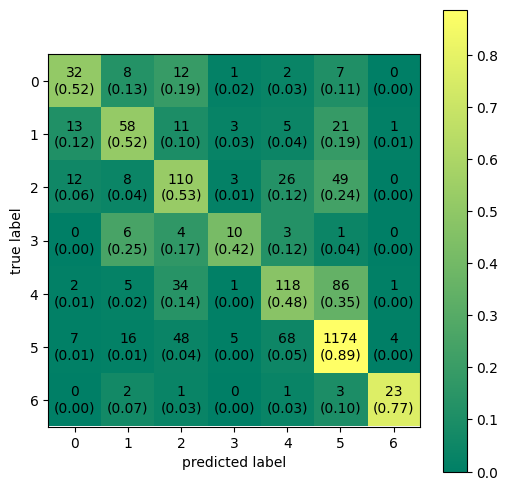

In [28]:
# Print confusion matrix and classification report for EfficientNet
test_acc, test_loss, all_preds, all_labels = test_step(model=eff_net,
                                                       test_dataloader=test_loader,
                                                       resize_model='eff',
                                                       loss_fn=nn.CrossEntropyLoss(),
                                                       accuracy_fn=accuracy_fn,
                                                       device=device)

conf_mat, report = plot_performance(all_preds, all_labels)

In [30]:
# Create table containing acc and weighted precision, recall and F1 for all models
metric_results = {}
for model in ['mlp', 'cnn']:
    for loss_fn in loss_fns:
        for optimizer in optimizers:
            loaded_model = None
            if model == 'mlp':
                loaded_model = MLP((3, 28, 28), n_classes)
                loaded_model.load_state_dict(torch.load(PATH / f"MLP_{str((optimizer, loss_fn))}.pth"))
            else:
                loaded_model = CNN((3, CNN_IMG_SIZE, CNN_IMG_SIZE), n_classes)
                loaded_model.load_state_dict(torch.load(PATH / f"CNN_{str((optimizer, loss_fn))}.pth"))
            loaded_model.to(device)
            loss = nn.CrossEntropyLoss() if (loss_fn == 'CEL') else nn.MultiMarginLoss()
            test_acc, test_loss, all_preds, all_labels = test_step(model=loaded_model,
                                                                   test_dataloader=test_loader,
                                                                   resize_model=model,
                                                                   loss_fn=loss,
                                                                   accuracy_fn=accuracy_fn,
                                                                   device=device)
            all_labels = [item for sublist in all_labels for item in sublist]
            all_preds = [item for sublist in all_preds for item in sublist]
            print(f"{model.upper()}_{str((optimizer, loss_fn))}")
            metric_results[f"{model.upper()}_{str((optimizer, loss_fn))}"] = {}
            metric_results[f"{model.upper()}_{str((optimizer, loss_fn))}"]['F1'] = f1_score(y_true=all_labels,
                                                                                            y_pred=all_preds,
                                                                                            average='weighted',
                                                                                            zero_division=0)
            metric_results[f"{model.upper()}_{str((optimizer, loss_fn))}"]['Precision'] = precision_score(y_true=all_labels,
                                                                                                          y_pred=all_preds,
                                                                                                          average='weighted',
                                                                                                          zero_division=0)
            metric_results[f"{model.upper()}_{str((optimizer, loss_fn))}"]['Recall'] = recall_score(y_true=all_labels,
                                                                                                    y_pred=all_preds,
                                                                                                    average='weighted',
                                                                                                    zero_division=0)
            metric_results[f"{model.upper()}_{str((optimizer, loss_fn))}"]['Accuracy'] = test_acc

test_acc, test_loss, all_preds, all_labels = test_step(model=eff_net,
                                                       test_dataloader=test_loader,
                                                       resize_model='eff',
                                                       loss_fn=nn.CrossEntropyLoss(),
                                                       accuracy_fn=accuracy_fn,
                                                       device=device)
all_labels = [item for sublist in all_labels for item in sublist]
all_preds = [item for sublist in all_preds for item in sublist]
metric_results["EFF_('Adam', 'CEL')"] = {}
metric_results["EFF_('Adam', 'CEL')"]['F1'] = f1_score(y_true=all_labels,
                                                      y_pred=all_preds,
                                                      average='weighted',
                                                      zero_division=0)
metric_results["EFF_('Adam', 'CEL')"]['Precision'] = precision_score(y_true=all_labels,
                                                                    y_pred=all_preds,
                                                                    average='weighted',
                                                                    zero_division=0)
metric_results["EFF_('Adam', 'CEL')"]['Recall'] = recall_score(y_true=all_labels,
                                                              y_pred=all_preds,
                                                              average='weighted',
                                                              zero_division=0)
metric_results["EFF_('Adam', 'CEL')"]['Accuracy'] = test_acc

pd.DataFrame.from_dict(metric_results, orient='index')

,F1,Precision,Recall,Accuracy
"MLP_('Adam', 'CEL')",0.717960,0.711947,0.731671,73.211739
"MLP_('RMSprop', 'CEL')",0.613543,0.605989,0.691771,69.181984
"MLP_('SGD', 'CEL')",0.653194,0.643078,0.700748,70.036194
"MLP_('Adam', 'MML')",0.696988,0.688921,0.723691,72.430489
"MLP_('RMSprop', 'MML')",0.636617,0.632084,0.690773,69.010223
"MLP_('SGD', 'MML')",0.602000,0.661446,0.685786,68.571350
"CNN_('Adam', 'CEL')",0.746827,0.745265,0.750125,74.919579
"CNN_('RMSprop', 'CEL')",0.678417,0.673348,0.711222,70.962776
"CNN_('SGD', 'CEL')",0.689934,0.683563,0.724190,72.454620
"CNN_('Adam', 'MML')",0.727730,0.724557,0.742145,74.138329
